# dunder method

Các phương thức này cho phép bạn quy định cách một đối tượng được khởi tạo, được gọi như hàm, được gán thuộc tính và được hiển thị khi in ra.

`__init__`: khởi tạo đối tượng; định nghĩa các layer

`__call__`: cho phép gọi đối tượng như một hàm; giúp pytorch đăng ký các layer khi bạn gán chúng vào model

`__setattr__`: xử lý việc gán giá trị cho thuộc tính; giúp bạn gọi model bằng model(x)

`__repr__`: quy định cách biểu diễn đối tượng dưới dạng chuỗi; giúp bạn xem cấu trúc model bằng print(model)

In [1]:
!pip install nbdev

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 83.9 MB/s  0:00:00
  Attempting uninstall: fastcore
    Found existing installation: fastcore 2.2.33
    Uninstalling fastcore-2.2.33:
      Successfully uninstalled fastcore-2.2.33
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [nbdev]


In [2]:
#|default_exp training

In [3]:
# |export
import pickle, gzip, math, os, time, shutil, torch, matplotlib as mpl, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from torch import tensor, nn
import torch.nn.functional as F

In [4]:
from fastcore.test import test_close

torch.set_printoptions(precision=2, linewidth=140, sci_mode=False)
np.set_printoptions(precision=2, linewidth=125)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray'

In [5]:
MNIST_URL = 'https://github.com/mnielsen/neural-networks-and-deep-learning/blob/master/data/mnist.pkl.gz?raw=true'
path_data = Path('data')
path_data.mkdir(exist_ok=True)
path_gz = path_data/'mnist.pkl.gz'

from urllib.request import urlretrieve
if not path_gz.exists(): urlretrieve(MNIST_URL, path_gz)

with gzip.open(path_gz, 'rb') as f:
  ((x_train,y_train), (x_valid, y_valid), _) = pickle.load(f, encoding='latin-1')
x_train,y_train, x_valid, y_valid = map(tensor, [x_train, y_train, x_valid, y_valid])

# initial setup

## data

In [6]:
n,m = x_train.shape
c = y_train.max() + 1
nh = 50

In [7]:
class Model(nn.Module):
  def __init__(self, n_in, nh, n_out):
    super().__init__()
    self.layers = [nn.Linear(n_in, nh), nn.ReLU(), nn.Linear(nh, n_out)]

  def __call__(self,x):
    for l in self.layers: x = l(x)
    return x

In [8]:
model = Model(m,nh,10)
pred = model(x_train)
pred.shape

torch.Size([50000, 10])

## cross entropy loss

First, we will need to compute the softmax of our activations. This is defined by:

$$\hbox{softmax(x)}_{i} = \frac{e^{x_{i}}}{e^{x_{0}} + e^{x_{1}} + \cdots + e^{x_{n-1}}}$$

or more concisely:

$$\hbox{softmax(x)}_{i} = \frac{e^{x_{i}}}{\sum\limits_{0 \leq j \lt n} e^{x_{j}}}$$

In practice, we will need the log of the softmax when we calculate the loss.

In [9]:
def log_softmax(x):
  return (x.exp()/(x.exp().sum(-1,keepdim=True))).log()

In [10]:
log_softmax(pred)

tensor([[-2.37, -2.49, -2.36,  ..., -2.31, -2.28, -2.22],
        [-2.37, -2.44, -2.44,  ..., -2.27, -2.26, -2.16],
        [-2.48, -2.33, -2.28,  ..., -2.30, -2.30, -2.27],
        ...,
        [-2.33, -2.52, -2.34,  ..., -2.31, -2.21, -2.16],
        [-2.38, -2.38, -2.33,  ..., -2.29, -2.26, -2.17],
        [-2.33, -2.55, -2.36,  ..., -2.29, -2.27, -2.16]], grad_fn=<LogBackward0>)

Note that the formula

$$\log \left ( \frac{a}{b} \right ) = \log(a) - \log(b)$$

gives a simplification when we compute the log softmax:

In [11]:
def log_softmax(x):
  return x - x.exp().sum(-1, keepdim=True).log()

Then, there is a way to compute the log of the sum of exponentials in a more stable way, called the [LogSumExp trick](https://en.wikipedia.org/wiki/LogSumExp). The idea is to use the following formula:

$$\log \left ( \sum_{j=1}^{n} e^{x_{j}} \right ) = \log \left ( e^{a} \sum_{j=1}^{n} e^{x_{j}-a} \right ) = a + \log \left ( \sum_{j=1}^{n} e^{x_{j}-a} \right )$$

where a is the maximum of the $x_{j}

Ý tưởng chính là: trừ một giá trị \(a\) khỏi các số mũ để tránh tràn số (overflow), sau đó cộng lại \(a\) ở bên ngoài log.

In [12]:
def logsumexp(x):
  # Tìm max theo chiều cuối cùng, ở đây chính là chiều 1, trả về tuple giá trị lớn nhất và vị trí của nó
  # x.max tra ve ket qua la cac gia tri lớn nhất [0] va vi tri cua no [1]
  m = x.max(-1)[0] # lấy giá trị lớn nhất
  return m + (x-m[:,None]).exp().sum(-1).log()

This way, we will avoid an overflow when taking the exponential of a big activation. In PyTorch, this is already implemented for us.

In [13]:
def log_softmax(x):
  return x - x.logsumexp(-1, keepdim=True)

In [14]:
test_close(logsumexp(pred), pred.logsumexp(-1))
sm_pred = log_softmax(pred)
sm_pred

tensor([[-2.37, -2.49, -2.36,  ..., -2.31, -2.28, -2.22],
        [-2.37, -2.44, -2.44,  ..., -2.27, -2.26, -2.16],
        [-2.48, -2.33, -2.28,  ..., -2.30, -2.30, -2.27],
        ...,
        [-2.33, -2.52, -2.34,  ..., -2.31, -2.21, -2.16],
        [-2.38, -2.38, -2.33,  ..., -2.29, -2.26, -2.17],
        [-2.33, -2.55, -2.36,  ..., -2.29, -2.27, -2.16]], grad_fn=<SubBackward0>)

The cross entropy loss for some target $x$ and some prediction $p(x)$ is given by:

$$ -\sum x\, \log p(x) $$

But since our $x$s are 1-hot encoded (actually, they're just the integer indices), this can be rewritten as $-\log(p_{i})$ where i is the index of the desired target.

This can be done using numpy-style [integer array indexing](https://docs.scipy.org/doc/numpy-1.13.0/reference/arrays.indexing.html#integer-array-indexing). Note that PyTorch supports all the tricks in the advanced indexing methods discussed in that link.

- x là nhãn thực tế và p(x) là xác suất mà mô hình dự đoán, dấu - giúp loss không âm
- vì là one hot encoding nên có 1 giá trị là 1 tại vị trí i của nhãn được dự đoán còn lại là 0 nên khi tính sẽ thành 0

In [15]:
y_train[:3]

tensor([5, 0, 4])

In [16]:
sm_pred[0,5], sm_pred[1,0], sm_pred[2,4]

(tensor(-2.20, grad_fn=<SelectBackward0>),
 tensor(-2.37, grad_fn=<SelectBackward0>),
 tensor(-2.36, grad_fn=<SelectBackward0>))

In [17]:
sm_pred[0][5]

tensor(-2.20, grad_fn=<SelectBackward0>)

In [18]:
sm_pred[[0,1,2], y_train[:3]]

tensor([-2.20, -2.37, -2.36], grad_fn=<IndexBackward0>)

input của nll là log_softmax()

In [19]:
def nll(input, target):
  return -input[range(target.shape[0]), target].mean()

In [20]:
loss = nll(sm_pred, y_train)
loss

tensor(2.30, grad_fn=<NegBackward0>)

use pytorch's implementation

In [21]:
test_close(F.nll_loss(F.log_softmax(pred, -1), y_train), loss, 1e-3)

In PyTorch, `F.log_softmax` and `F.nll_loss` are combined in one optimized function, `F.cross_entropy`.

In [22]:
test_close(F.cross_entropy(pred, y_train), loss, 1e-3)

# basic training loop

Basically the training loop repeats over the following steps:
- get the output of the model on a batch of inputs
- compare the output to the labels we have and compute a loss
- calculate the gradients of the loss with respect to every parameter of the model
- update said parameters with those gradients to make them a little bit better

In [23]:
loss_func = F.cross_entropy

In [24]:
bs = 50 # batch size
xb = x_train[0:bs] # a mini batch from x
preds = model(xb) # predictions
preds[0], preds.shape

(tensor([-0.09, -0.21, -0.08,  0.10, -0.04,  0.08, -0.04, -0.03,  0.01,  0.06], grad_fn=<SelectBackward0>),
 torch.Size([50, 10]))

In [25]:
yb = y_train[0:bs]
yb

tensor([5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9, 4, 0, 9, 1, 1, 2, 4, 3, 2, 7, 3, 8, 6, 9, 0, 5, 6, 0, 7, 6, 1, 8, 7, 9,
        3, 9, 8, 5, 9, 3])

In [26]:
loss_func(preds, yb)

tensor(2.30, grad_fn=<NllLossBackward0>)

In [27]:
preds.argmax(dim=1)

tensor([3, 9, 3, 8, 5, 9, 3, 9, 3, 9, 5, 3, 9, 9, 3, 9, 9, 5, 8, 7, 9, 5, 3, 8, 9, 5, 9, 5, 5, 9, 3, 5, 9, 7, 5, 7, 9, 9, 3, 9, 3, 5, 3, 8,
        3, 5, 9, 5, 9, 5])

In [28]:
#|export
def accuracy(out, yb): return (out.argmax(dim=1)==yb).float().mean()

In [29]:
accuracy(preds, yb)

tensor(0.08)

In [30]:
lr = 0.5 # learning rate
epochs = 3 # how many epochs to train for

In [31]:
#|export
def report(loss, preds, yb):
  print(f"{loss:.2f},  {accuracy(preds, yb):.2f}")

In [32]:
xb, yb = x_train[0:bs], y_train[0:bs]
preds = model(xb)
report(loss_func(preds, yb), preds, yb)

2.30,  0.08


In [33]:
for epoch in range(epochs):
  for i in range(0, n, bs):
    s = slice(i, min(n,i+bs))
    xb,yb = x_train[s], y_train[s]
    preds = model(xb)
    loss = loss_func(preds, yb)
    loss.backward()
    with torch.no_grad():
      for l in model.layers:
        if hasattr(l, 'weight'): # kiểm tra layer l có thuộc tính tên là weight hay không
          # đk chỉ kiểm tra weight nhưng code bên trong có bias
          # vì vậy layer có weight cũng có bias và gradient tương ứng
          l.weight -= l.weight.grad * lr
          l.bias   -= l.bias.grad   * lr
          l.weight.grad.zero_()
          l.bias  .grad.zero_()
  report(loss, preds, yb)

0.12,  0.98
0.12,  0.94
0.08,  0.96


# using parameters and optim

## parameters

Vì m1 kế thừa cơ chế quản lý module của nn.Module, khi bạn gán một layer PyTorch vào thuộc tính của nó, layer đó sẽ được đăng ký như một submodule. Vì vậy, PyTorch có thể tìm thấy các tham số của layer này khi gọi:

In [34]:
m1 = nn.Module()
m1.foo = nn.Linear(3,4) # foo: tên thuộc tính tự đặt để lưu layer vào m1
m1

Module(
  (foo): Linear(in_features=3, out_features=4, bias=True)
)

In [35]:
list(m1.named_children())

[('foo', Linear(in_features=3, out_features=4, bias=True))]

In [36]:
list(m1.parameters())

[Parameter containing:
 tensor([[ 0.57,  0.43, -0.30],
         [ 0.13, -0.32, -0.24],
         [ 0.51,  0.04,  0.22],
         [ 0.13, -0.17, -0.24]], requires_grad=True),
 Parameter containing:
 tensor([-0.01, -0.51, -0.39,  0.56], requires_grad=True)]

In [37]:
class MLP(nn.Module):
  def __init__(self, n_in, nh, n_out):
    super().__init__()
    self.l1 = nn.Linear(n_in, nh) # submodule của model
    self.l2 = nn.Linear(nh, n_out) # submodule của model
    self.relu = nn.ReLU() # submodule của model

  def forward(self, x):
    return self.l2(self.relu(self.l1(x)))

In [38]:
model = MLP(m,nh,10)
model.l1

Linear(in_features=784, out_features=50, bias=True)

In [39]:
model

MLP(
  (l1): Linear(in_features=784, out_features=50, bias=True)
  (l2): Linear(in_features=50, out_features=10, bias=True)
  (relu): ReLU()
)

In [40]:
for name, l in model.named_children():
  print(f'{name}: {l}')

l1: Linear(in_features=784, out_features=50, bias=True)
l2: Linear(in_features=50, out_features=10, bias=True)
relu: ReLU()


In [41]:
for p in model.parameters():
  print(p.shape)

torch.Size([50, 784])
torch.Size([50])
torch.Size([10, 50])
torch.Size([10])


In [42]:
def fit():
  for epoch in range(epochs):
    for i in range(0,n,bs):
      s = slice(i,min(n,i+bs))
      xb, yb = x_train[s], y_train[s]
      preds = model(xb)
      loss = loss_func(preds, yb)
      loss.backward()
      with torch.no_grad():
        for p in model.parameters():
          p -= p.grad * lr
        model.zero_grad()
    report(loss, preds, yb)

In [43]:
fit()

0.19,  0.96
0.11,  0.96
0.04,  1.00


việc gán self.l1 = nn.Linear(...) và self.l2 = nn.Linear(...) giúp PyTorch đăng ký các layer con (submodule). Sau đó, model.parameters() tự tìm các tham số của chúng (weight, bias) để bạn cập nhật trong quá trình training.

In [44]:
class MyModule:
  def __init__(self, n_in, nh, n_out):
    self._modules = {}
    self.l1 = nn.Linear(n_in, nh)
    self.l2 = nn.Linear(nh, n_out)

  def __setattr__(self,k,v):
    if not k.startswith("_"): self._modules[k] = v
    super().__setattr__(k,v)

  def __repr__(self): return f'{self._modules}'

  def parameters(self):
    for l in self._modules.values(): yield from l.parameters()

In [45]:
mdl = MyModule(m,nh,10)
mdl

{'l1': Linear(in_features=784, out_features=50, bias=True), 'l2': Linear(in_features=50, out_features=10, bias=True)}

In [46]:
for p in mdl.parameters(): print(p.shape)

torch.Size([50, 784])
torch.Size([50])
torch.Size([10, 50])
torch.Size([10])


## registering modules

In [47]:
from functools import reduce

We can use the original layers approach, but we have to register the modules.

In [48]:
layers = [nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10)]

In [49]:
class Model(nn.Module):
  def __init__(self, layers):
    super().__init__()
    self.layers = layers
    for i,l in enumerate(self.layers):
      self.add_module(f'layer_{i}', l)

  def forward(self, x):
    return reduce(lambda val,layer: layer(val), self.layers, x)

In [50]:
model = Model(layers)
model

Model(
  (layer_0): Linear(in_features=784, out_features=50, bias=True)
  (layer_1): ReLU()
  (layer_2): Linear(in_features=50, out_features=10, bias=True)
)

In [51]:
model(xb).shape

torch.Size([50, 10])

## nn.ModuleList

`nn.ModuleList` does this for us

In [52]:
class SequentialModel(nn.Module):
  def __init__(self, layers):
    super().__init__()
    self.layers = nn.ModuleList(layers)

  def forward(self, x):
    for l in self.layers: x = l(x)
    return x

In [53]:
model = SequentialModel(layers)
model

SequentialModel(
  (layers): ModuleList(
    (0): Linear(in_features=784, out_features=50, bias=True)
    (1): ReLU()
    (2): Linear(in_features=50, out_features=10, bias=True)
  )
)

In [54]:
fit()

0.12,  0.96
0.11,  0.96
0.07,  0.98


## nn.Sequential

In [55]:
model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))

In [56]:
fit()
loss_func(model(xb), yb), accuracy(model(xb), yb)

0.15,  0.96
0.11,  0.96
0.09,  0.94


(tensor(0.02, grad_fn=<NllLossBackward0>), tensor(1.))

In [57]:
model

Sequential(
  (0): Linear(in_features=784, out_features=50, bias=True)
  (1): ReLU()
  (2): Linear(in_features=50, out_features=10, bias=True)
)

## optim

In [58]:
class Optimizer():
  def __init__(self, params, lr=0.5):
    self.params, self.lr = list(params), lr

  def step(self):
   with torch.no_grad():
    for p in self.params: p -= p.grad * self.lr

  def zero_grad(self):
    for p in self.params: p.grad.data.zero_()

In [59]:
model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))

In [60]:
opt = Optimizer(model.parameters())

In [61]:
for epoch in range(epochs):
  for i in range(0, n, bs):
    s = slice(i, min(n,i+bs))
    xb, yb = x_train[s], y_train[s]
    preds = model(xb)
    loss = loss_func(preds, yb)
    loss.backward()
    opt.step()
    opt.zero_grad()
  report(loss, preds, yb)

0.18,  0.94
0.13,  0.96
0.11,  0.94


PyTorch already provides this exact functionality in `optim.SGD` (it also handles stuff like momentum, which we'll look at later)

In [62]:
from torch import optim

In [63]:
def get_model():
  model = nn.Sequential(nn.Linear(m,nh), nn.ReLU(), nn.Linear(nh,10))
  return model, optim.SGD(model.parameters(), lr=lr)

In [64]:
model, opt = get_model()
loss_func(model(xb), yb)

tensor(2.33, grad_fn=<NllLossBackward0>)

In [65]:
for epoch in range(epochs):
  for i in range(0,n,bs):
    s = slice(i, min(n,i+bs))
    xb, yb = x_train[s], y_train[s]
    preds = model(xb)
    loss = loss_func(preds, yb)
    loss.backward()
    opt.step()
    opt.zero_grad()
  report(loss, preds, yb)

0.12,  0.98
0.09,  0.98
0.07,  0.98


# dataset and dataloader

## dataset

It's clunky to iterate through minibatches of x and y values separately:

```python
    xb = x_train[s]
    yb = y_train[s]
```

Instead, let's do these two steps together, by introducing a `Dataset` class:

```python
    xb,yb = train_ds[s]

In [66]:
#|export
class Dataset():
  def __init__(self, x, y): self.x, self.y = x, y
  def __len__(self): return len(self.x)
  def __getitem__(self, i): return self.x[i], self.y[i]

In [67]:
train_ds, valid_ds = Dataset(x_train, y_train), Dataset(x_valid, y_valid)
assert len(train_ds)==len(x_train)
assert len(valid_ds)==len(x_valid)

In [68]:
xb, yb = train_ds[0:5]
assert xb.shape==(5,28*28)
assert yb.shape==(5,)
xb,yb

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([5, 0, 4, 1, 9]))

In [69]:
model, opt = get_model()

In [70]:
for epoch in range(epochs):
  for i in range(0,n,bs):
    xb,yb = train_ds[i:min(n,i+bs)]
    preds = model(xb)
    loss = loss_func(preds, yb)
    loss.backward()
    opt.step()
    opt.zero_grad()
  report(loss, preds, yb)

0.17,  0.96
0.11,  0.94
0.09,  0.96


## dataloader

Previously, our loop iterated over batches (xb, yb) like this:

```python
for i in range(0, n, bs):
    xb,yb = train_ds[i:min(n,i+bs)]
    ...
```

Let's make our loop much cleaner, using a data loader:

```python
for xb,yb in train_dl:
    ...
```

In [71]:
class DataLoader():
  def __init__(self, ds, bs): self.ds, self.bs = ds, bs
  def __iter__(self):
    for i in range(0, len(self.ds), self.bs):
      yield self.ds[i:i+self.bs]

In [72]:
train_dl = DataLoader(train_ds, bs)
valid_dl = DataLoader(valid_ds, bs)

In [73]:
xb,yb = next(iter(valid_dl))
xb.shape

torch.Size([50, 784])

In [74]:
yb

tensor([3, 8, 6, 9, 6, 4, 5, 3, 8, 4, 5, 2, 3, 8, 4, 8, 1, 5, 0, 5, 9, 7, 4, 1, 0, 3, 0, 6, 2, 9, 9, 4, 1, 3, 6, 8, 0, 7, 7, 6, 8, 9, 0, 3,
        8, 3, 7, 7, 8, 4])

tensor(3)

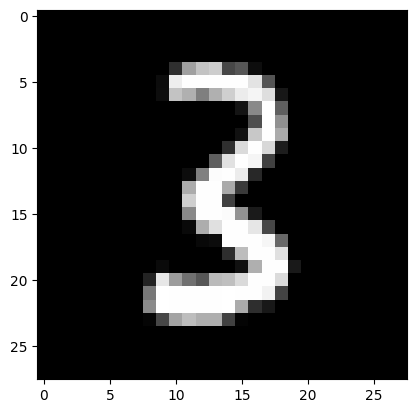

In [75]:
plt.imshow(xb[0].view(28,28))
yb[0]

In [76]:
model, opt = get_model()

In [77]:
def fit():
  for epoch in range(epochs):
    for xb,yb in train_dl:
      preds = model(xb)
      loss = loss_func(preds, yb)
      loss.backward()
      opt.step()
      opt.zero_grad()
    report(loss, preds, yb)

In [78]:
fit()
loss_func(model(xb), yb), accuracy(model(xb), yb)

0.11,  0.98
0.09,  0.98
0.06,  1.00


(tensor(0.03, grad_fn=<NllLossBackward0>), tensor(1.))

## random sampling

We want our training set to be in a random order, and that order should differ each iteration. But the validation set shouldn't be randomized.

In [79]:
import random

In [80]:
class Sampler():
  def __init__(self,ds,shuffle=False):
    self.n, self.shuffle = len(ds), shuffle

  def __iter__(self):
    res = list(range(self.n))
    if self.shuffle: random.shuffle(res)
    return iter(res)

In [81]:
from itertools import islice

In [82]:
ss = Sampler(train_ds) # là một đối tượng tạo iterator

In [83]:
it = iter(ss)
for o in range(5): print(next(it)) # next là lấy từng giá trị trong ds

0
1
2
3
4


In [84]:
# islice tạo một iterator chỉ duyệt qua 5 phần tử đầu tiên
# dùng list để lấy các phần tử từ iterator và đưa vào danh sách
list(islice(ss,5))

[0, 1, 2, 3, 4]

In [85]:
ss = Sampler(train_ds, shuffle=True)
list(islice(ss,5))

[48178, 10511, 30921, 7010, 32024]

In [86]:
import fastcore.all as fc

In [87]:
class BatchSampler():
  def __init__(self, sampler, bs, drop_last=False):
    # drop_last = False: giữ lại batch cuối cùng ngay cả khi không đủ 4 phần tử
    fc.store_attr()

  def __iter__(self):
    yield from fc.chunked(iter(self.sampler), self.bs, drop_last=self.drop_last)

- `iter(self.sampler)`: Tạo iterator từ Sampler, lần lượt sinh ra các chỉ số của dataset.

Ví dụ, nếu ss.n = 10 và shuffle=False, các chỉ số là:
```python
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
```

- `fc.chunked(..., self.bs, ...)`

Chia các phần tử thành từng nhóm có kích thước tối đa là self.bs = 4.

Với 10 chỉ số, kết quả là:
```python
[0, 1, 2, 3]
[4, 5, 6, 7]
[8, 9]
```
Vì `drop_last=False`, nhóm cuối chỉ có 2 phần tử vẫn được giữ lại.

- `yield from`

`fc.chunked()` tạo ra các batch lần lượt. yield from chuyển tiếp từng batch đó cho iterator của `BatchSampler`.

**mỗi lần yield, một batch được trả ra; không cần tạo toàn bộ danh sách batch ngay lập tức.**

In [88]:
batchs = BatchSampler(ss,4)
list(islice(batchs, 5))

[[28373, 42181, 32559, 5836],
 [18965, 29297, 6987, 43228],
 [8788, 12545, 7241, 7651],
 [12207, 37104, 46224, 29683],
 [43915, 12411, 4568, 43399]]

In [89]:
def collate(b):
  xs, ys = zip(*b)
  return torch.stack(xs), torch.stack(ys)

Giả sử b chứa 3 mẫu dữ liệu lấy từ dataset, mỗi mẫu gồm input x và nhãn y:
```python
b = [
    (x1, y1),
    (x2, y2),
    (x3, y3)
]
```

Dấu * dùng để unpack các phần tử của b làm đối số cho zip(): `xs, ys = zip(*b)` tương đương với `zip((x1, y1), (x2, y2), (x3, y3))`

zip() gom các phần tử cùng vị trí lại với nhau, tạo ra hai nhóm:
```python
xs = (x1, x2, x3)
ys = (y1, y2, y3)
```

ghép các tensor thành một tensor mới, thêm một chiều mới ở đầu: `torch.stack(xs), torch.stack(ys)`
```python
# input
x1 = torch.tensor([1., 2.])
x2 = torch.tensor([3., 4.])
x3 = torch.tensor([5., 6.])

torch.stack((x1, x2, x3))
```
```python
# output
tensor([[1., 2.],
        [3., 4.],
        [5., 6.]])
```

*collate() nhận nhiều mẫu riêng lẻ và chuyển chúng thành hai tensor batch: một tensor chứa inputs và một tensor chứa labels.*

**Lưu ý: các tensor trong cùng nhóm phải có shape tương thích để torch.stack() hoạt động.**

In [90]:
class DataLoader():
  def __init__(self, ds, batchs, collate_fn=collate):
    fc.store_attr()

  def __iter__(self):
    yield from (self.collate_fn(self.ds[i] for i in b) for b in self.batchs)

lặp qua từng batchs `for b in self.batchs`
```python
b = [5, 2, 8, 1]
b = [7, 0, 4, 3]
...
```
lấy dữ liệu thực tế `self.ds[i] for i in b`
```python
train_ds[5]
train_ds[2]
train_ds[8]
train_ds[1]
```
Mỗi lần truy cập trả về một mẫu dữ liệu, chẳng hạn (x5, y5), (x2, y2), (x8, y8), (x1,y1)

*Biểu thức này là một generator expression, nên các mẫu được tạo ra lần lượt khi cần, không nhất thiết phải tạo sẵn toàn bộ danh sách.*

hàm collate sau đó làm như trên

`yield from` đây là generator expression lồng nhau: vòng ngoài duyệt qua từng batch chỉ số, vòng trong lấy dữ liệu rồi gom thành tensor.

`yield from `lần lượt trả về kết quả của từng batch sau khi đã qua `collate_fn`.



In [91]:
train_samp = BatchSampler(Sampler(train_ds, shuffle=True),bs)
valid_samp = BatchSampler(Sampler(valid_ds, shuffle=False),bs)

In [92]:
train_dl = DataLoader(train_ds, batchs=train_samp)
valid_dl = DataLoader(valid_ds, batchs=valid_samp)

tensor(3)

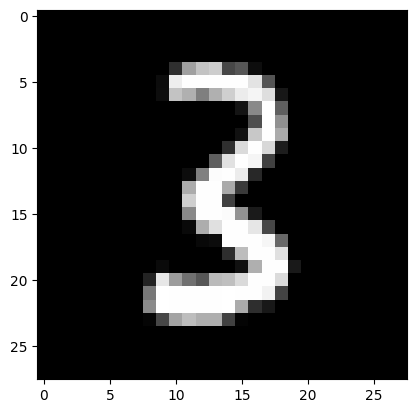

In [93]:
xb,yb = next(iter(valid_dl))
plt.imshow(xb[0].view(28,28))
yb[0]

In [94]:
xb.shape, yb.shape

(torch.Size([50, 784]), torch.Size([50]))

In [95]:
model, opt = get_model()

In [96]:
fit()

0.11,  0.98
0.10,  0.98
0.04,  0.98


## multiprocessing DataLoader

In [97]:
import torch.multiprocessing as mp
from fastcore.basics import store_attr

In [98]:
train_ds[[3,6,8,1,2]]

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([1, 1, 1, 0, 4]))

In [99]:
train_ds.__getitem__([3,6,8,1,2])

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([1, 1, 1, 0, 4]))

In [100]:
for o in map(train_ds.__getitem__, ([3,6],[8,1])): print(o)

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]), tensor([1, 1]))
(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
        [0., 0., 0.,  ..., 0., 0., 0.]]), tensor([1, 0]))


n_workers là số process được tạo để xử lý dữ liệu song song.
- n_workers=1: tạo một process worker.
- n_workers=4: tạo bốn process worker.

 *Lưu ý, mp.Pool(1) vẫn tạo một worker process riêng, không có nghĩa là chạy ngay trong process chính.*

 ex là đối tượng quản lý nhóm process đó.

 with đảm bảo pool được quản lý và đóng lại khi thoát khỏi khối lệnh.

Với n_workers=2 thì dataloader-process chính sẽ gửi công việc cho 2 worker được tạo trên. Đây là cách hình dung về xử lý song song; việc phân công cụ thể phụ thuộc vào cách các công việc được gửi tới pool.

sau đó sẽ xử lý như vòng lặp for o ở trên


In [101]:
class DataLoader():
  def __init__(self, ds, batchs, n_workers=1, collate_fn=collate):
    fc.store_attr()

  def __iter__(self):
    with mp.Pool(self.n_workers) as ex:
      yield from ex.map(self.ds.__getitem__, iter(self.batchs))

In [102]:
train_dl = DataLoader(train_ds, batchs=train_samp, n_workers=2)
it = iter(train_dl)

In [103]:
xb,yb = next(it)
xb.shape, yb.shape

(torch.Size([50, 784]), torch.Size([50]))

## pytorch dataloader

In [104]:
#|export
from torch.utils.data import DataLoader, SequentialSampler, RandomSampler, BatchSampler

In [105]:
train_samp = BatchSampler(RandomSampler(train_ds), bs, drop_last=False)
valid_samp = BatchSampler(SequentialSampler(valid_ds), bs, drop_last=False)

In [106]:
train_dl = DataLoader(train_ds, batch_sampler=train_samp, collate_fn=collate)
valid_dl = DataLoader(valid_ds, batch_sampler=valid_samp, collate_fn=collate)

In [107]:
model, opt = get_model()
fit()
loss_func(model(xb), yb), accuracy(model(xb), yb)

0.11,  0.96
0.11,  0.96
0.25,  0.98


(tensor(0.03, grad_fn=<NllLossBackward0>), tensor(1.))

PyTorch can auto-generate the BatchSampler for us:

In [108]:
train_dl = DataLoader(train_ds, bs, sampler=RandomSampler(train_ds), collate_fn=collate)
valid_dl = DataLoader(valid_ds, bs, sampler=SequentialSampler(valid_ds), collate_fn=collate)

PyTorch can also generate the Sequential/RandomSamplers too:

In [109]:
train_dl = DataLoader(train_ds, bs, shuffle=True, drop_last=True, num_workers=2)
valid_dl = DataLoader(valid_ds, bs, shuffle=False, num_workers=2)

In [110]:
model, opt = get_model()
fit()
loss_func(model(xb), yb), accuracy(model(xb), yb)

0.21,  0.92
0.15,  0.94
0.05,  0.98


(tensor(0.02, grad_fn=<NllLossBackward0>), tensor(1.))

Our dataset actually already knows how to sample a batch of indices all at once:

In [111]:
train_ds[[4,6,7]]

(tensor([[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]),
 tensor([9, 1, 3]))

...that means that we can actually skip the batch_sampler and collate_fn entirely:

Với torch.utils.data.DataLoader chuẩn của PyTorch, khi truyền sampler=train_samp, luồng xử lý mặc định là:
1. DataLoader duyệt qua train_samp.
2. Mỗi lần duyệt, BatchSampler trả về một danh sách chỉ số, ví dụ [4, 6, 7].
3. DataLoader lấy danh sách đó làm một phần tử của sampler và gọi dataset với phần tử này.
4. Nếu dataset hỗ trợ truy cập bằng danh sách chỉ số, nó có thể trả về cả batch.
Vì thế, code có thể chạy đúng nhờ train_ds hỗ trợ train_ds[[4, 6, 7]].

In [112]:
# sampler: chỉ số từng mẫu
# batch_sampler: ds chỉ số của cả batch
train_dl = DataLoader(train_ds, sampler=train_samp)
valid_dl = DataLoader(valid_ds, sampler=valid_samp)

Dataset thông thường

Giả sử dataset chỉ hỗ trợ lấy từng mẫu:

```python
train_ds[4]  # (x4, y4)
```

Với DataLoader chuẩn của PyTorch:

```python
DataLoader(train_ds, sampler=my_sampler, batch_size=3)
```
Khi đó:
- sampler sinh từng chỉ số, ví dụ 4, 6, 7.
- batch_sampler sinh một danh sách chỉ số, ví dụ [4, 6, 7].

Còn nếu dùng:

```python
DataLoader(train_ds, batch_sampler=my_batch_sampler)
```

thì `my_batch_sampler` đã quyết định các chỉ số được gom thành từng batch như thế nào.

# validation

You **always** should also have a [validation set](http://www.fast.ai/2017/11/13/validation-sets/), in order to identify if you are overfitting.

We will calculate and print the validation loss at the end of each epoch.

(Note that we always call `model.train()` before training, and `model.eval()` before inference, because these are used by layers such as `nn.BatchNorm2d` and `nn.Dropout` to ensure appropriate behaviour for these different phases.)

In [113]:
#|export
def fit(epochs, model, loss_func, opt, train_dl, valid_dl):
  for epoch in range(epochs):
    model.train()
    for xb,yb in train_dl:
        loss = loss_func(model(xb), yb)
        loss.backward()
        opt.step()
        opt.zero_grad()

    model.eval()
    with torch.no_grad():
        tot_loss,tot_acc,count = 0.,0.,0
        for xb,yb in valid_dl:
            pred = model(xb)
            n = len(xb)
            count += n
            tot_loss += loss_func(pred,yb).item()*n
            tot_acc  += accuracy (pred,yb).item()*n
    print(epoch, tot_loss/count, tot_acc/count)
  return tot_loss/count, tot_acc/count

In [114]:
#|export
def get_dls(train_ds, valid_ds, bs, **kwargs):
  return(DataLoader(train_ds, batch_size=bs, shuffle=True,**kwargs),
         DataLoader(valid_ds, batch_size=bs*2, **kwargs))

Now, our whole process of obtaining the data loaders and fitting the model can be run in 3 lines of code:

In [115]:
train_dl, valid_dl = get_dls(train_ds, valid_ds,bs)
model, opt = get_model()

In [116]:
%time loss,acc = fit(5, model, loss_func, opt, train_dl, valid_dl)

0 0.14841486441902815 0.9566000026464462
1 0.11900197795126587 0.9663000047206879
2 0.12275693108560518 0.9624000042676926
3 0.10854795794235543 0.9684000056982041
4 0.11104105117497966 0.9689000046253204
CPU times: user 7.3 s, sys: 13.1 ms, total: 7.31 s
Wall time: 7.33 s


# export

**1.nbdev là gì và dùng để làm gì?**

Hãy tưởng tượng bạn đang học PyTorch và viết code trong một notebook như training.ipynb. Bạn có thể viết hàm, chạy thử, xem kết quả, vẽ biểu đồ và ghi chú giải thích ngay bên cạnh code.

Cách làm này rất thuận tiện khi học và thử nghiệm. Nhưng khi dự án lớn dần, bạn có thể gặp một số vấn đề:
- Code nằm rải rác trong nhiều notebook.
- Muốn sử dụng lại một hàm ở notebook khác thì phải sao chép code hoặc chạy lại notebook chứa hàm đó.
- Khi cần dùng code trong một chương trình Python thông thường, bạn phải chuyển code từ notebook sang file .py.
- Khi sửa một hàm, bạn có thể phải sửa nhiều bản sao của cùng hàm ở nhiều nơi.
- Code và tài liệu giải thích dễ bị tách rời nhau.
nbdev là một công cụ giúp bạn xây dựng dự án Python bằng notebook, đồng thời xuất phần code được chọn thành các module Python thông thường.

**2. Một dự án nbdev gồm những gì?**

Trước hết, cần phân biệt hai khái niệm:
- **Notebook** là một file `.ipynb`, nơi bạn viết và chạy code.
- **Dự án nbdev** là một thư mục dự án có cấu trúc và cấu hình để nbdev biết đọc notebook nào, xuất code đi đâu và quản lý package như thế nào.
Bạn có thể có một notebook chứa hàng chục ô `#| export` nhưng vẫn chưa có một dự án nbdev hợp lệ. Đây chính là điểm liên quan trực tiếp đến lỗi bạn gặp.

**2.1. Cấu trúc của một dự án**

Một dự án nbdev thường có cấu trúc tương tự như sau:

Thư mục gốc

my_project/(thư mục lớn)

  pyproject.toml
  
  File cấu hình dự án theo nbdev hiện đại (nbdev 3).

  nbs/(thư mục nhỏ)

  Chứa các notebook nguồn, nơi bạn viết code và tài liệu.

    00_core.ipynb

    01_training.ipynb

  my_project/(thư mục nhỏ)

  Package Python chứa các module được xuất ra.

    core.py

    training.py

    __init__.py


Đây là ví dụ minh họa; tên file và cấu trúc thực tế có thể khác. Một số dự án còn có README.md, thư mục kiểm thử, cấu hình GitHub Actions và các file phục vụ tạo tài liệu.

Hãy hiểu nhiệm vụ của từng phần:

| Thành phần | Vai trò |
|---|---|
| pyproject.toml | Cho nbdev biết thông tin package và cấu hình dự án. |
| nbs/ | Chứa notebook nguồn. |
| export | Đánh dấu ô code cần đưa vào module Python. |
| Thư mục package | Chứa code Python được tạo ra từ notebook. |
| __init__.py | Giúp tổ chức package và có thể xác định những thành phần được cung cấp khi import. |

Các dự án nbdev cũ, đặc biệt những tài liệu sử dụng nbdev 2 trở về trước, thường có settings.ini thay cho pyproject.toml. Từ nbdev 3, cấu hình đã chuyển sang pyproject.toml; do đó, bạn cần xác định phiên bản đang sử dụng trước khi làm theo một hướng dẫn cụ thể

**2.2. Notebook nguồn và file .py khác nhau như thế nào?**

Giả sử bạn đang viết notebook nbs/01_training.ipynb.

Trong notebook, bạn có thể có nhiều ô:
Ô 1 — import thư viện
```python
import torch
import torch.nn as nn
```
Ô 2 — định nghĩa hàm cần tái sử dụng
```python
#| export

def mse(pred, target):
    return ((pred - target) ** 2).mean()
```
Ô 3 — thử nghiệm
```python
pred = torch.tensor([1.0, 2.0])
target = torch.tensor([1.0, 3.0])

mse(pred, target)
```
Ô 4 — giải thích bằng Markdown
```python
Hàm mse tính trung bình bình phương sai số giữa
giá trị dự đoán và giá trị mục tiêu.
```
Bốn ô này phục vụ những mục đích khác nhau:
- Ô import giúp notebook sử dụng thư viện.
- Ô có #| export chứa code muốn đưa vào package.
- Ô thử nghiệm giúp bạn kiểm tra hàm ngay trong notebook.
- Ô Markdown giải thích ý tưởng cho người đọc.

Khi export, nbdev sử dụng các chỉ thị để xác định nội dung cần đưa vào module. Ví dụ, hàm `mse` có thể được xuất thành `my_project/training.py`, trong khi ô thử nghiệm không tự động trở thành một phần của module chỉ vì nó nằm cùng notebook.

Vì vậy, `#| export` không phải lệnh chạy hàm và cũng không phải lệnh tạo file ngay khi bạn thực thi ô notebook. Nó là một chỉ thị cho quá trình xử lý notebook của nbdev.

**2.3. Vậy nbdev có ích gì ngoài việc chuyển notebook thành .py?**

Chuyển code sang .py chỉ là một phần chức năng. Khi dự án được thiết lập đầy đủ, nbdev còn hỗ trợ:
- Tái sử dụng code: import hàm và lớp từ package của bạn.
- Tạo tài liệu: kết hợp code, phần giải thích và ví dụ trong notebook để xây dựng tài liệu.
- Kiểm thử: chạy các ví dụ và ô kiểm thử trong notebook để phát hiện lỗi.
- Quản lý dự án: hỗ trợ quy trình Git, kiểm tra code và tự động hóa các bước chuẩn bị dự án.
- Đóng gói thư viện: tổ chức code để có thể cài đặt và sử dụng như một package Python.

Những chức năng bổ sung này có ích khi bạn phát triển một thư viện hoặc dự án tương đối lớn. Nếu mục tiêu duy nhất là lấy code từ một notebook thành file Python, bạn chưa nhất thiết cần toàn bộ hệ thống nbdev.

In [118]:
#import nbdev; nbdev.nbdev_export()

In [119]:
!pip show nbdev

Name: nbdev
Version: 3.3.27
Summary: Create delightful software with Jupyter Notebooks
Home-page: 
Author: 
Author-email: "Jeremy Howard and the fast.ai community" <j@fast.ai>
License-Expression: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: asttokens, astunparse, build, execnb, fastcore, fastgit, ghapi, pyyaml, setuptools, watchdog
Required-by: 


In [120]:
import os

print("Thư mục hiện tại:", os.getcwd())
print("Các file trong thư mục:")
print(os.listdir("."))

Thư mục hiện tại: /content
Các file trong thư mục:
['.config', 'data', 'sample_data']


In [122]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: mount failed